In [3]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [6]:
output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
z = gpd.read_file(output_shp_path)
z.columns

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'LULC', 'Ref_dem', 'geometry'],
      dtype='object')

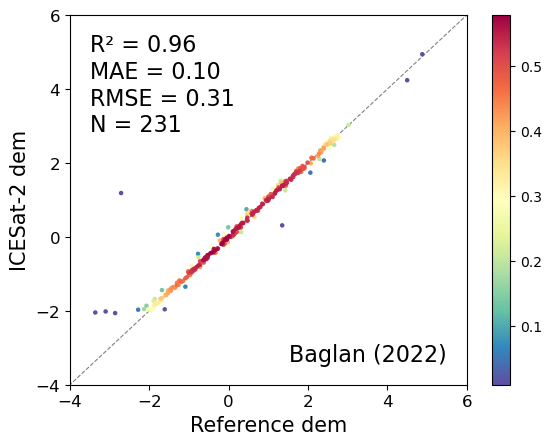

In [ ]:
import rasterio
import geopandas as gpd

region = 'Region4'
location = 'Severn'
location2 = 'Baglan'

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year_list = [2020]

#-------------------- For ICESat-2 Validation-----------------------

for j in range(len(year_list)):
# 路径  
    year = year_list[j]
    shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid.shp"
    #shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_final.shp"
    # shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid.shp"
    output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid_kk.shp"
    # output_csv_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.csv"
    raster_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    retrieved_DEM_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_4_RF_FB6_new9_bys.tif"

        # 1. 读取 shp 点数据
    points = gpd.read_file(shp_path)

    # 2. 打开栅格数据
    with rasterio.open(raster_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
            
            # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = [val[0] for val in src.sample(coords)]
    points['Ref_dem'] = values
    with rasterio.open(retrieved_DEM_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
            
            # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values_dem = [val[0] for val in src.sample(coords)]

        # 5. 将像元值添加到 GeoDataFrame 中
    points['Re_dem'] = values_dem
    
        # 6. 保存结果
    points.to_file(output_shp_path)
    # points[['geometry', 'raster_val', 'OH']].to_csv(output_csv_path, index=False)
    z = points[['geometry', 'Ref_dem', 'OH', 'Re_dem']]
    z = z[z!=-999]
    z = z[z!=6]
    z = z[z!=0]
    z = z[z['Ref_dem'] > -60]
    z = z.dropna()

    # x = np.array(z['raster_val'])
    # y = np.array(z['OH'])


    #     #R, _ = pearsonr(y, x)
    # R = r2_score(y, x)
    # MAD = np.mean(np.abs(y-x))
    # MSB = np.mean((y-x))
    # RMSE = np.sqrt(np.mean((y-x)**2))
    # num = int(len(x))
    
    x = np.array(z['Ref_dem'])  # 参考值 / 真值
    y = np.array(z['OH'])          # 预测值

    # 以 x 为真实值，y 为预测值进行评价
    R = r2_score(x, y)  # R²
    MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
    MSB = np.mean(x - y)          # Mean Signed Bias
    RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
    num = len(x)
        

    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('ICESat-2 dem', fontsize = 15)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(x, y, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

        # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
        # plt.colorbar()

    ax.set_xlim(-4, 6)
    ax.set_ylim(-4, 6)
    ax.set_yticks(np.arange(-4, 6.1, 2))
    ax.tick_params(axis='both', labelsize=12)
    # plt.show()

    # output_path = f"G:/ICESat-2/ICESat_validation/{location2}/ICESat_{location2}_{year}_AAA.png"  # 例如："./output/plot.png"
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    # plt.close()
    # plt.show()

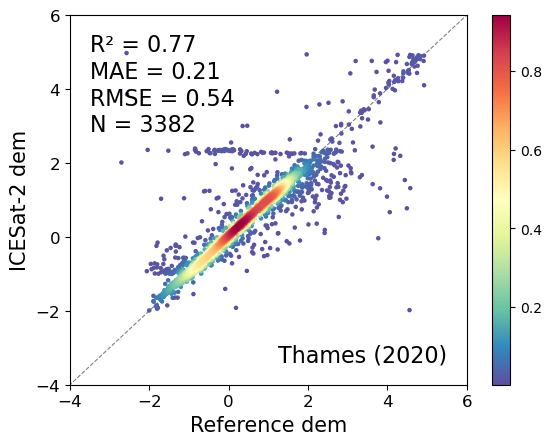

In [6]:
import rasterio
import geopandas as gpd

region = 'Region1'
location = 'Thames'
location2 = 'Thames'

year_list = [2019, 2020, 2021, 2022, 2023]
year_list = [2020]

#-------------------- For ICESat-2 Validation-----------------------

for j in range(len(year_list)):
# 路径  
    year = year_list[j]
    #shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_final.shp"
    shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp"
    output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid.shp"
    # output_shp_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10_valid_kk.shp"
    output_csv_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.csv"
    raster_path = f"G:\DTM_ref\{location2}\{location2}_{year}_2\{location2}_masked_{year}1.tif"
    retrieved_DEM_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_4_RF_FB6_new9_bys.tif"

        # 1. 读取 shp 点数据
    points = gpd.read_file(shp_path)

    # 2. 打开栅格数据
    with rasterio.open(raster_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
            
            # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values = [val[0] for val in src.sample(coords)]
    points['Ref_dem'] = values
    with rasterio.open(retrieved_DEM_path) as src:
        raster_crs = src.crs  # 获取 raster 的坐标系
            
            # 3. 如果坐标系不同，则重投影点数据
        if points.crs != raster_crs:
        # print(f"坐标系不一致，正在从 {points.crs} 转换为 {raster_crs}")
            points = points.to_crs(raster_crs)

        # 4. 获取坐标并提取像元值（默认波段 1）
        coords = [(geom.x, geom.y) for geom in points.geometry]
        values_dem = [val[0] for val in src.sample(coords)]

        # 5. 将像元值添加到 GeoDataFrame 中
    points['Re_dem'] = values_dem
    
        # 6. 保存结果
    # points.to_file(output_shp_path)
    # points[['geometry', 'raster_val', 'OH']].to_csv(output_csv_path, index=False)
    z = points[['geometry', 'Ref_dem', 'OH', 'Re_dem']]
    z = z[z['Ref_dem']!=-999]
    z = z[z['Ref_dem']!=6]
    z = z[z['Ref_dem']!=0]
    z = z.dropna()


    x = np.array(z['Ref_dem'])  # 参考值 / 真值
    y = np.array(z['OH'])          # 预测值

    # 以 x 为真实值，y 为预测值进行评价
    R = r2_score(x, y)  # R²
    MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
    MSB = np.mean(x - y)          # Mean Signed Bias
    RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
    num = len(x)
        

    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('ICESat-2 dem', fontsize = 15)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(x, y, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

        # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
        # plt.colorbar()

    ax.set_xlim(-4, 6)
    ax.set_ylim(-4, 6)
    ax.set_yticks(np.arange(-4, 6.1, 2))
    ax.tick_params(axis='both', labelsize=12)
    # plt.show()

    # output_path = f"G:/ICESat-2/ICESat_validation/{location2}/ICESat_{location2}_{year}_AAA.png"  # 例如："./output/plot.png"
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    # plt.close()
    # plt.show()

In [6]:
points.columns


Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'LULC', 'Ref_dem', 'geometry'],
      dtype='object')

In [27]:
raster_path = 'G:\DTM_ref\Carmarthen/test.tif'
qq = rxr.open_rasterio(raster_path, masked=True)
qq_clipped = qq.where(qq <= 6, 6)
output_path= 'G:\DTM_ref\Carmarthen/test_masked_2021_2.tif'
qq_clipped.rio.to_raster(output_path)


C:\Users\minyu\AppData\Local\Temp\ipykernel_47680\439496237.py:94: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(validation_sample_path)
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'retrieved_dem' to 'retrieved_'
  ogr_write(


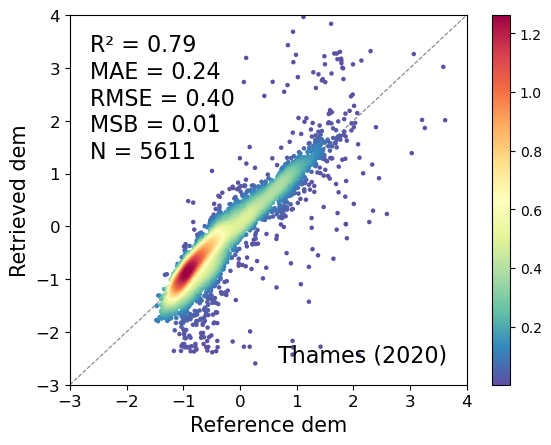

In [ ]:
#-------------------------------for Retrieval DTM validation----------------------------

region = 'Region1'
location = 'Thames1'
location2 = 'Thames'
method = 'RF'
Bands = 4
year_num = 'bys'
year_list = [2020]

for i in range(len(year_list)):
    
    year = year_list[i]
    ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}_2\{location2}_masked_{year}1.tif"
    # ref_dem_path = 'G:\DTM_ref\Carmarthen\Carmarthen_2021\Carmarthen_masked_2021.tif'
    #retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new10_AAA.tif"
    retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new9_{year_num}.tif"
    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.shp'
    validation_sample_csv_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.csv'

    validation_sample_path = 'G:\ICESat-2\Discussion51_new\Validation_point_Thames2020.shp'
    
    with rasterio.open(ref_dem_path) as src1, rasterio.open(retrieved_dem_path) as src2:
        # 计算交集区域（bounding box）
        bounds1 = src1.bounds
        bounds2 = src2.bounds

        intersection = box(
            max(bounds1.left, bounds2.left),
            max(bounds1.bottom, bounds2.bottom),
            min(bounds1.right, bounds2.right),
            min(bounds1.top, bounds2.top)
        )

        if intersection.is_empty:
            raise ValueError("两个 raster 没有空间交集")

        # 统一坐标系（假设两个 raster 已经在同一坐标系，否则需要 reproject）

        # 设置目标分辨率与 shape
        res = 30
        width = int((intersection.bounds[2] - intersection.bounds[0]) / res)
        height = int((intersection.bounds[3] - intersection.bounds[1]) / res)
        transform = from_origin(intersection.bounds[0], intersection.bounds[3], res, res)

        # 重采样并裁剪两个 raster 到相同区域和分辨率
        def reproject_to_common(src):
            dst_array = np.empty((height, width), dtype=src.read(1).dtype)
            reproject(
                source=rasterio.band(src, 1),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=src.crs,
                resampling=Resampling.nearest
            )
            return dst_array

        data1 = reproject_to_common(src1)
        data2 = reproject_to_common(src2)
        crs = src1.crs

    # 创建有效掩膜
    mask1 = (data1 != src1.nodata) & (data1 != 6) & (data1 != 0) & (data1 != -999)
    mask2 = (data2 != src2.nodata) & (data2 != 0) & (data2 != 0) & (data2 != -999)
    valid_mask = mask1 & mask2

    valid_indices = np.argwhere(valid_mask)

    if len(valid_indices) == 0:
        raise ValueError("没有满足条件的像元")

    # 随机抽样点
    n_points = int(len(valid_indices)/30)
    sampled_indices = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

    points = []
    vals1 = []
    vals2 = []

    for row, col in sampled_indices:
        x, y = transform * (col + 0.5, row + 0.5)
        points.append(Point(x, y))
        vals1.append(data1[row, col])
        vals2.append(data2[row, col])

    gdf = gpd.GeoDataFrame({
        'Refer_dem': vals1,
        'retrieved_dem': vals2
    }, geometry=points, crs=crs)

    # 保存结果
    # gdf.to_file(validation_sample_path)
    # gdf.to_csv(validation_sample_csv_path)
    
    z = gdf.dropna()

    x = z['Refer_dem']
    y = z['retrieved_dem']
    y = np.array(y)
    x = np.array(x)

    # R, _ = pearsonr(y, x)
    R2 = r2_score(x, y)
    MAD = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))


    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('Retrieved dem', fontsize = 15)
    ax.plot([-3, 6], [-3, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

    ax.set_xlim(-3, 4)
    ax.set_ylim(-3, 4)
    ax.tick_params(axis='both', labelsize=12)
        
    # output_path = f"G:/ICESat-2/Retrieval_DTM_validation/{location2}/{location2}_{year}_{Bands}_{year_num}_bys.png"  # 例如："./output/plot.png"
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    # plt.close()

In [1]:
def scatter_plot_draw(z, x_name, y_name, xy_lim, band, method, output_path):

    #z = gdf.dropna()

    # x = z['Refer_dem']
    # y = z['retrieved_dem']
    x = z[x_name]
    y = z[y_name].astype(float)
    y = np.array(y)
    x = np.array(x)

    # R, _ = pearsonr(y, x)
    R2 = r2_score(y, x)
    MAD = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))


    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
    name = f'{location2}_{method}_{band} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('Retrieved dem', fontsize = 15)
    ax.plot([-3, 6], [-3, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

    ax.set_xlim(xy_lim[0], xy_lim[1])
    ax.set_ylim(xy_lim[0], xy_lim[1])
    ax.tick_params(axis='both', labelsize=12)
        
    #output_path = f"G:/ICESat-2/Retrieval_DTM_validation/{location2}/{location2}_{year}.png"  # 例如："./output/plot.png"
    plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    plt.close()

In [22]:
# ---------------------------- Discussion test ------------------------------------------------
import geopandas as gpd
import rasterio
from shapely.geometry import Point

# 参数设定
region = 'Region2'
location = 'wash_bay'
location2 = 'Wash'
method = 'RF'
Bands_list = [3]
year_list = [2019, 2020, 2021, 2022, 2023, 2024]

# 遍历每一年
for year in year_list:
    # 输入输出路径
    validation_sample_path = f'G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_sample_points.shp'
    output_path = f'G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_sample_points_.shp'
    
    # 读取样本点
    gdf = gpd.read_file(validation_sample_path)

    for Bands in Bands_list:
        # 构建不同高程图路径
        #path_all = f"G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_{Bands}_{method}_FB6_new10_AAA.tif"
        # path_sy  = f"G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_{Bands}_{method}_FB6_new10_SY.tif"
        # path_band1_all = f"G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_1_{method}_FB6_new10_AAA.tif"
        #path_band_linear = f"G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_Freq_Linear_FB6_new10_AAA.tif"
        path_band1_poly = f"G:/ICESat-2/{region}_map/{location}_map/A{year}/{location}_{year}_3_{method}_FB6_new10_AAA.tif"
        
        def sample_raster_to_gdf(gdf, raster_path, column_name):
            with rasterio.open(raster_path) as src:
                if gdf.crs != src.crs:
                    gdf = gdf.to_crs(src.crs)
                coords = [(point.x, point.y) for point in gdf.geometry]
                values = [v[0] if v else None for v in src.sample(coords)]
                gdf[column_name] = values
            return gdf

        # gdf = sample_raster_to_gdf(gdf, path_band_linear, f"R_DTM_linear_all")
        gdf = sample_raster_to_gdf(gdf, path_band1_poly, 'RF_3_all')
        # gdf = sample_raster_to_gdf(gdf, path_band1_all, f"R_DTM_1_All")

    # 保存结果
    gdf.to_file(output_path)


In [24]:
region = 'Region2'
location = 'wash_bay'
location2 = 'Wash'
method = 'RF'

Bands = 3
year_range = 'ALL'
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
retrieved_name = 'RF_3_all'

for i in range(len(year_list)):
    
    year = year_list[i]
    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_.shp'
    #validation_sample_csv_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_.csv'
    #output = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_.shp'
    
    points = gpd.read_file(validation_sample_path)

    plot_output_path =  f"G:/ICESat-2/Retrieval_DTM_validation/{location2}/{location2}_{year}_{method}_{Bands}_{year_range}.png"
    scatter_plot_draw(points, 'Refer_dem', retrieved_name ,[-3, 4], Bands, method, plot_output_path)